# Session 3 · Advanced Supervised Learning: Regression Techniques

[![Open In Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/Hamnakhan123/Diploma-in-Data-Science/blob/main/term-2/03-advanced-data-science-with-python/code/session-03-advanced-regression-techniques.ipynb)

Diploma in Data Science · Prepared by **Hamna Zahid Khan**, Junior Lecturer

Run the cells from top to bottom. Every example is self-contained, so you can also run any single cell on its own.

### Example 1 · Basic: polynomial regression and overfitting

degree  train RMSE  test RMSE
    1        4.48       4.83
    3        4.15       4.33
   15        3.88       4.61


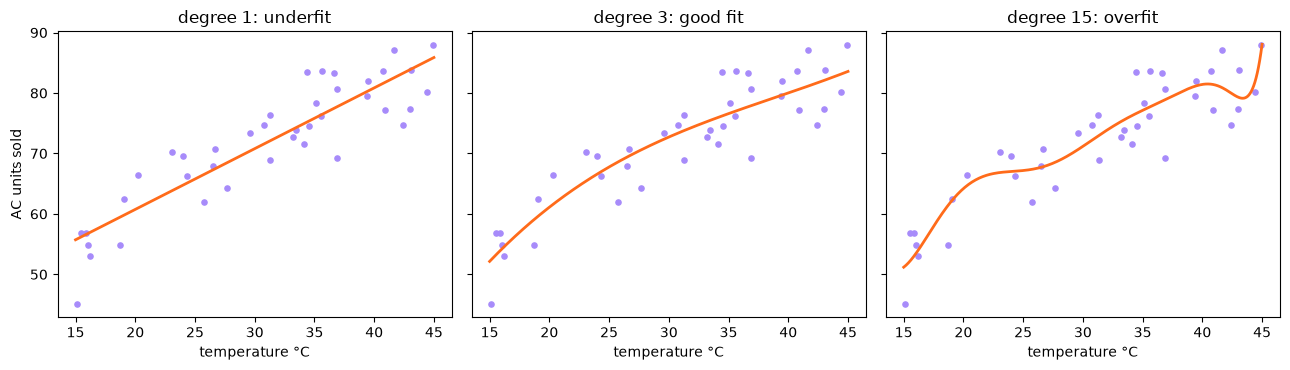

In [1]:
"""Fit polynomials of increasing degree and watch underfitting turn into overfitting."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error

rng = np.random.default_rng(0)
# Air-conditioner sales vs temperature: rises then flattens (a curve, not a line)
temp = np.sort(rng.uniform(15, 45, 40))
sales = 50 + 30 * np.sin((temp - 15) / 18) + rng.normal(0, 4, 40)
temp_test = rng.uniform(15, 45, 200)
sales_test = 50 + 30 * np.sin((temp_test - 15) / 18) + rng.normal(0, 4, 200)

grid = np.linspace(15, 45, 300).reshape(-1, 1)
fig, ax = plt.subplots(1, 3, figsize=(13, 3.8), sharey=True)
print("degree  train RMSE  test RMSE")
for i, d in enumerate([1, 3, 15]):
    model = make_pipeline(PolynomialFeatures(d), StandardScaler(), LinearRegression())
    model.fit(temp.reshape(-1, 1), sales)
    tr = mean_squared_error(sales, model.predict(temp.reshape(-1, 1))) ** .5
    te = mean_squared_error(sales_test, model.predict(temp_test.reshape(-1, 1))) ** .5
    print(f"{d:>5}   {tr:>9.2f}  {te:>9.2f}")
    ax[i].scatter(temp, sales, s=14, color="#A78BFA")
    ax[i].plot(grid, np.clip(model.predict(grid), 0, 120), color="#FF6B1A", lw=2)
    ax[i].set_title(f"degree {d}: " + ["underfit", "good fit", "overfit"][i]); ax[i].set_xlabel("temperature °C")
ax[0].set_ylabel("AC units sold")
fig.tight_layout(); fig.savefig("session-03_polynomial_fits.png", dpi=110); plt.show()

### Example 2 · Intermediate: Ridge and Lasso coefficient paths

feature   OLS     Ridge(a=100)  Lasso(a=5)
age       -0.5         0.4         0.0
sex      -11.4        -8.4        -2.2
bmi       24.7        21.4        24.2
bp        15.4        13.3        10.3
s1       -37.7        -2.1        -0.0
s2        22.7        -3.7        -0.0
s3         4.8        -9.0        -7.0
s4         8.4         5.7         0.0
s5        35.7        18.7        21.2
s6         3.2         4.7         0.0
Lasso(alpha=5) keeps 5 of 10 features: ['sex', 'bmi', 'bp', 's3', 's5']


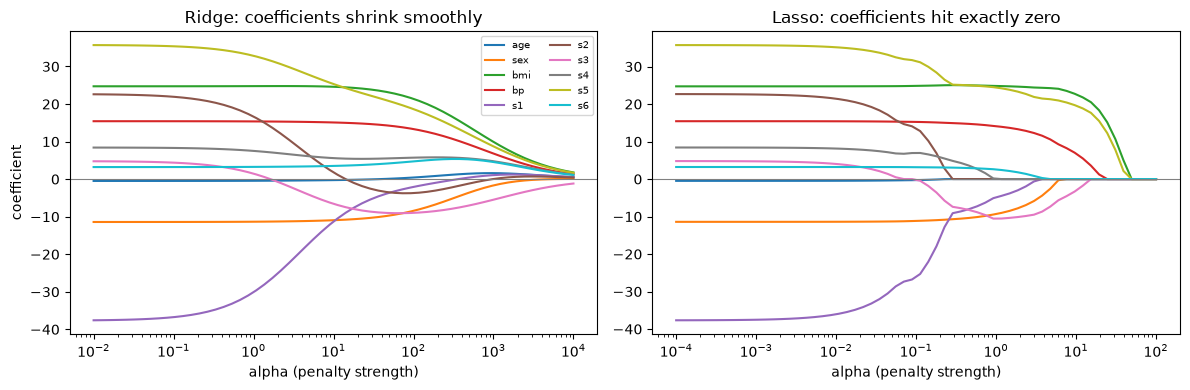

In [2]:
"""How Ridge and Lasso coefficients shrink as alpha grows (diabetes data, 10 features)."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.datasets import load_diabetes
from sklearn.linear_model import Ridge, Lasso, LinearRegression
from sklearn.preprocessing import StandardScaler

data = load_diabetes()
X = StandardScaler().fit_transform(data.data); y = data.target
names = data.feature_names
alphas = np.logspace(-2, 4, 60)
ridge = np.array([Ridge(alpha=a).fit(X, y).coef_ for a in alphas])
lasso = np.array([Lasso(alpha=a / 100, max_iter=20000).fit(X, y).coef_ for a in alphas])

ols = LinearRegression().fit(X, y).coef_
print("feature   OLS     Ridge(a=100)  Lasso(a=5)")
r100 = Ridge(alpha=100).fit(X, y).coef_; l5 = Lasso(alpha=5).fit(X, y).coef_
for n, a, b, c in zip(names, ols, r100, l5):
    print(f"{n:<6}{a:>8.1f}{b:>12.1f}{c:>12.1f}")
print("Lasso(alpha=5) keeps", int((l5 != 0).sum()), "of 10 features:", [n for n, c in zip(names, l5) if c != 0])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
for j in range(X.shape[1]):
    ax[0].plot(alphas, ridge[:, j], label=names[j]); ax[1].plot(alphas / 100, lasso[:, j])
ax[0].set_xscale("log"); ax[1].set_xscale("log")
ax[0].set_title("Ridge: coefficients shrink smoothly"); ax[1].set_title("Lasso: coefficients hit exactly zero")
for a in ax: a.set_xlabel("alpha (penalty strength)"); a.axhline(0, color="grey", lw=.8)
ax[0].set_ylabel("coefficient"); ax[0].legend(fontsize=7, ncol=2)
fig.tight_layout(); fig.savefig("session-03_regularisation_paths.png", dpi=110); plt.show()

### Example 3 · Intermediate: regularisation rescues an overfit model

In [3]:
"""40 rows and 60 features (only 5 useful): compare OLS, Ridge, Lasso and ElasticNet with CV-chosen alpha."""
import numpy as np
from sklearn.linear_model import LinearRegression, RidgeCV, LassoCV, ElasticNetCV
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import make_pipeline
from sklearn.metrics import mean_squared_error, r2_score

rng = np.random.default_rng(42)
n, p = 120, 60
X = rng.normal(size=(n, p))
true_w = np.zeros(p); true_w[:5] = [8, -6, 5, 4, -3]          # only the first 5 matter
y = X @ true_w + rng.normal(0, 4, n)
X_tr, X_te, y_tr, y_te = train_test_split(X, y, train_size=40, random_state=0)

alphas = np.logspace(-3, 3, 30)
models = {
    "OLS (no penalty)": LinearRegression(),
    "RidgeCV": RidgeCV(alphas=alphas),
    "LassoCV": LassoCV(alphas=alphas, cv=5, max_iter=50000, random_state=0),
    "ElasticNetCV": ElasticNetCV(alphas=alphas, l1_ratio=[.2, .5, .8], cv=5, max_iter=50000, random_state=0),
}
print(f"{'model':<18}{'train R2':>9}{'test R2':>9}{'test RMSE':>11}  non-zero coefs  alpha")
for name, m in models.items():
    pipe = make_pipeline(StandardScaler(), m).fit(X_tr, y_tr)
    est = pipe[-1]
    nz = int((np.abs(est.coef_) > 1e-6).sum())
    a = getattr(est, "alpha_", "-")
    print(f"{name:<18}{r2_score(y_tr, pipe.predict(X_tr)):>9.2f}{r2_score(y_te, pipe.predict(X_te)):>9.2f}"
          f"{mean_squared_error(y_te, pipe.predict(X_te)) ** .5:>11.2f}  {nz:>14}  {a if a == '-' else round(a, 3)}")
lasso = make_pipeline(StandardScaler(), models["LassoCV"]).fit(X_tr, y_tr)[-1]
print("\nLasso's largest coefficients at positions:", np.argsort(-np.abs(lasso.coef_))[:5])

model              train R2  test R2  test RMSE  non-zero coefs  alpha
OLS (no penalty)       1.00     0.40      10.43              60  -
RidgeCV                0.99     0.46       9.96              60  3.29
LassoCV                0.98     0.91       4.11              20  0.304
ElasticNetCV           0.99     0.85       5.20              37  0.117

Lasso's largest coefficients at positions: [0 1 2 3 4]


### Example 4 · Advanced: trees, forests, boosting and SVR on a non-linear problem

In [4]:
"""Compare linear and non-linear regressors with 5-fold cross-validation on a curved, interacting target."""
import numpy as np
from sklearn.model_selection import cross_validate, KFold
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.tree import DecisionTreeRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.neighbors import KNeighborsRegressor

rng = np.random.default_rng(1)
n = 800
X = rng.uniform(0, 10, size=(n, 4))
# delivery time (min): grows with distance, worse in rush hour, interaction rain x distance
y = 10 + 3 * X[:, 0] + 8 * np.sin(X[:, 1]) + 0.8 * X[:, 0] * (X[:, 2] > 7) + rng.normal(0, 2, n)

models = {
    "Baseline (mean)": DummyRegressor(),
    "Linear regression": LinearRegression(),
    "Ridge": make_pipeline(StandardScaler(), Ridge(1.0)),
    "KNN (k=10)": make_pipeline(StandardScaler(), KNeighborsRegressor(10)),
    "Decision tree (depth 6)": DecisionTreeRegressor(max_depth=6, random_state=0),
    "Random forest": RandomForestRegressor(n_estimators=200, random_state=0, n_jobs=-1),
    "Gradient boosting": GradientBoostingRegressor(random_state=0),
    "SVR (RBF)": make_pipeline(StandardScaler(), SVR(C=30, epsilon=0.5)),
}
cv = KFold(5, shuffle=True, random_state=0)
print(f"{'model':<25}{'MAE':>7}{'RMSE':>7}{'R2':>7}")
for name, m in models.items():
    r = cross_validate(m, X, y, cv=cv, scoring=("neg_mean_absolute_error", "neg_root_mean_squared_error", "r2"))
    print(f"{name:<25}{-r['test_neg_mean_absolute_error'].mean():>7.2f}"
          f"{-r['test_neg_root_mean_squared_error'].mean():>7.2f}{r['test_r2'].mean():>7.3f}")

model                        MAE   RMSE     R2
Baseline (mean)             9.14  11.17 -0.006
Linear regression           4.93   5.92  0.716
Ridge                       4.93   5.92  0.716
KNN (k=10)                  3.57   4.44  0.840
Decision tree (depth 6)     3.18   4.07  0.865


Random forest               2.24   2.87  0.933


Gradient boosting           1.87   2.42  0.952
SVR (RBF)                   3.02   3.78  0.884


### Example 5 · Advanced: validation curve for choosing alpha

alpha      0.001   train R2 0.607   validation R2 0.393
alpha      0.010   train R2 0.606   validation R2 0.391
alpha      0.100   train R2 0.604   validation R2 0.392
alpha      1.000   train R2 0.602   validation R2 0.418
alpha     10.000   train R2 0.594   validation R2 0.450
alpha    100.000   train R2 0.566   validation R2 0.470
alpha   1000.000   train R2 0.403   validation R2 0.353
alpha  10000.000   train R2 0.107   validation R2 0.075
best alpha = 100.00 with validation R2 = 0.470


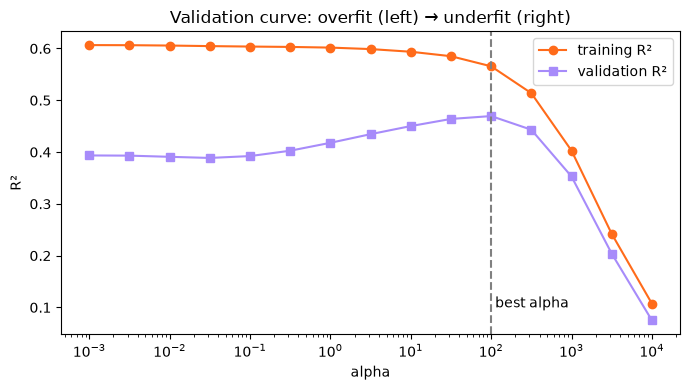

In [5]:
"""Use a validation curve to see underfitting and overfitting as Ridge alpha changes."""
import numpy as np
import matplotlib.pyplot as plt
from sklearn.model_selection import validation_curve
from sklearn.pipeline import make_pipeline
from sklearn.preprocessing import PolynomialFeatures, StandardScaler
from sklearn.linear_model import Ridge
from sklearn.datasets import load_diabetes

X, y = load_diabetes(return_X_y=True)
pipe = make_pipeline(PolynomialFeatures(2), StandardScaler(), Ridge())   # 65 features incl. interactions
alphas = np.logspace(-3, 4, 15)
tr, va = validation_curve(pipe, X, y, param_name="ridge__alpha", param_range=alphas, cv=5, scoring="r2")
best = alphas[va.mean(1).argmax()]
for a, t, v in zip(alphas[::2], tr.mean(1)[::2], va.mean(1)[::2]):
    print(f"alpha {a:>10.3f}   train R2 {t:.3f}   validation R2 {v:.3f}")
print(f"best alpha = {best:.2f} with validation R2 = {va.mean(1).max():.3f}")

plt.figure(figsize=(7, 4))
plt.semilogx(alphas, tr.mean(1), "o-", color="#FF6B1A", label="training R²")
plt.semilogx(alphas, va.mean(1), "s-", color="#A78BFA", label="validation R²")
plt.axvline(best, ls="--", color="grey"); plt.text(best, .1, " best alpha")
plt.xlabel("alpha"); plt.ylabel("R²"); plt.title("Validation curve: overfit (left) → underfit (right)"); plt.legend()
plt.tight_layout(); plt.savefig("session-03_validation_curve.png", dpi=110); plt.show()

### 🏙️ Real-life data problem: pricing used cars

rows after cleaning: 2495 | missing mileage: 80
Baseline (mean)    CV MAE =  11.06 lakh
Ridge              CV MAE =   1.36 lakh


Lasso              CV MAE =   1.36 lakh


Gradient boosting  CV MAE =   1.34 lakh



TEST: MAE = 1.39 lakh, R2 = 0.975
MAE by make (lakh):
 make
Honda      1.62
Hyundai    2.90
Kia        1.69
Suzuki     0.55
Toyota     1.91

Suggested price for a 2019 Toyota 1300cc automatic, 85,000 km: Rs 27.5 lakh


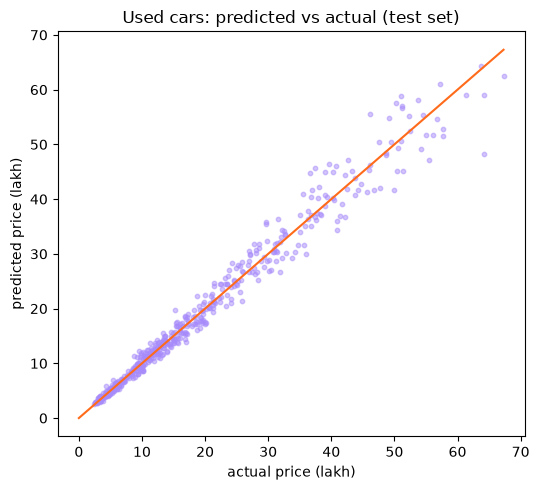

In [6]:
"""Real-life problem: used-car price prediction with a full preprocessing pipeline and model comparison."""
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split, cross_val_score, KFold
from sklearn.compose import ColumnTransformer, TransformedTargetRegressor
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.dummy import DummyRegressor
from sklearn.linear_model import RidgeCV, LassoCV
from sklearn.ensemble import HistGradientBoostingRegressor
from sklearn.metrics import mean_absolute_error, r2_score

rng = np.random.default_rng(7)
n = 2500
make = rng.choice(["Suzuki", "Toyota", "Honda", "Kia", "Hyundai"], n, p=[.35, .25, .2, .1, .1])
base = pd.Series(make).map({"Suzuki": 22, "Toyota": 48, "Honda": 45, "Kia": 52, "Hyundai": 50}).values
year = rng.integers(2008, 2026, n)
engine = np.where(make == "Suzuki", rng.choice([660, 1000, 1300], n), rng.choice([1300, 1500, 1800, 2000], n))
mileage = ((2026 - year) * rng.normal(14000, 4000, n)).clip(1000)
auto = rng.random(n) < 0.55
city = rng.choice(["Karachi", "Lahore", "Islamabad", "Peshawar"], n)
price = base * (0.92 ** (2026 - year)) * (engine / 1300) ** .6 * (1 + .08 * auto) * np.exp(-mileage / 900000) \
        * np.where(city == "Islamabad", 1.04, 1.0) * np.exp(rng.normal(0, .08, n))      # lakh Rs
cars = pd.DataFrame({"make": make, "year": year, "engine_cc": engine, "mileage_km": mileage.round(-2),
                     "transmission": np.where(auto, "Automatic", "Manual"), "city": city, "price_lakh": price.round(2)})
cars.loc[rng.choice(n, 80, replace=False), "mileage_km"] = np.nan       # missing values
cars.loc[rng.choice(n, 5, replace=False), "price_lakh"] = 0.01          # data-entry errors

cars = cars[cars["price_lakh"] > 1]                                      # 1. remove impossible prices
print("rows after cleaning:", len(cars), "| missing mileage:", cars["mileage_km"].isna().sum())
X, y = cars.drop(columns="price_lakh"), cars["price_lakh"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=0.2, random_state=0)

num, cat = ["year", "engine_cc", "mileage_km"], ["make", "transmission", "city"]
prep = ColumnTransformer([
    ("num", Pipeline([("impute", SimpleImputer(strategy="median")), ("scale", StandardScaler())]), num),
    ("cat", OneHotEncoder(handle_unknown="ignore"), cat)])

def model(reg):            # predict log(price), report in lakh: handles skew and multiplicative effects
    return TransformedTargetRegressor(Pipeline([("prep", prep), ("reg", reg)]), func=np.log, inverse_func=np.exp)

candidates = {"Baseline (mean)": DummyRegressor(),
              "Ridge": model(RidgeCV(alphas=np.logspace(-3, 3, 13))),
              "Lasso": model(LassoCV(cv=5, random_state=0)),
              "Gradient boosting": model(HistGradientBoostingRegressor(random_state=0))}
cv = KFold(5, shuffle=True, random_state=1)
for name, m in candidates.items():
    s = -cross_val_score(m, X_tr, y_tr, cv=cv, scoring="neg_mean_absolute_error").mean()
    print(f"{name:<18} CV MAE = {s:6.2f} lakh")

best = candidates["Gradient boosting"].fit(X_tr, y_tr)
pred = best.predict(X_te)
print(f"\nTEST: MAE = {mean_absolute_error(y_te, pred):.2f} lakh, R2 = {r2_score(y_te, pred):.3f}")
err = pd.DataFrame({"make": X_te["make"], "abs_err": np.abs(y_te - pred)})
print("MAE by make (lakh):\n", err.groupby("make")["abs_err"].mean().round(2).to_string())
sample = pd.DataFrame({"make": ["Toyota"], "year": [2019], "engine_cc": [1300], "mileage_km": [85000],
                       "transmission": ["Automatic"], "city": ["Karachi"]})
print(f"\nSuggested price for a 2019 Toyota 1300cc automatic, 85,000 km: Rs {best.predict(sample)[0]:.1f} lakh")

plt.figure(figsize=(5.5, 5))
plt.scatter(y_te, pred, s=10, alpha=.5, color="#A78BFA"); m_ = y_te.max()
plt.plot([0, m_], [0, m_], color="#FF6B1A"); plt.xlabel("actual price (lakh)"); plt.ylabel("predicted price (lakh)")
plt.title("Used cars: predicted vs actual (test set)"); plt.tight_layout()
plt.savefig("session-03_car_predictions.png", dpi=110); plt.show()

### 🧩 Mini project: house rent estimator

In [7]:
"""Mini project: apartment rent estimator with model comparison, tuning and a saved pipeline."""
import numpy as np
import pandas as pd
import joblib
from sklearn.model_selection import train_test_split, cross_val_score, GridSearchCV
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.linear_model import RidgeCV
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.metrics import mean_absolute_error

rng = np.random.default_rng(3)
n = 1500
area = rng.choice(["DHA", "Gulshan", "Clifton", "North Nazimabad", "Saddar"], n)
size = rng.normal(1200, 350, n).clip(400, 3000)
beds = np.clip((size / 450).round() + rng.integers(-1, 2, n), 1, 6)
floor = rng.integers(0, 15, n)
lift = (floor > 3) | (rng.random(n) < .3)
area_mult = pd.Series(area).map({"DHA": 1.6, "Clifton": 1.5, "Gulshan": 1.0, "North Nazimabad": .9, "Saddar": .8}).values
rent = (30 * size * area_mult + 6000 * beds + 3000 * lift - 800 * floor * (~lift) + rng.normal(0, 5000, n)) / 1000
df = pd.DataFrame({"area": area, "size_sqft": size.round(), "bedrooms": beds, "floor": floor,
                   "lift": lift.astype(int), "rent_k": rent.round(1)})

X, y = df.drop(columns="rent_k"), df["rent_k"]
X_tr, X_te, y_tr, y_te = train_test_split(X, y, test_size=.2, random_state=0)
prep = ColumnTransformer([("num", StandardScaler(), ["size_sqft", "bedrooms", "floor", "lift"]),
                          ("cat", OneHotEncoder(handle_unknown="ignore"), ["area"])])
models = {"ridge": RidgeCV(), "forest": RandomForestRegressor(200, random_state=0, n_jobs=-1),
          "boosting": GradientBoostingRegressor(random_state=0)}
for name, reg in models.items():
    mae = -cross_val_score(Pipeline([("prep", prep), ("reg", reg)]), X_tr, y_tr, cv=5,
                           scoring="neg_mean_absolute_error").mean()
    print(f"{name:<9} CV MAE: Rs {mae:.1f}k")

search = GridSearchCV(Pipeline([("prep", prep), ("reg", GradientBoostingRegressor(random_state=0))]),
                      {"reg__n_estimators": [100, 300], "reg__max_depth": [2, 3, 4]},
                      cv=5, scoring="neg_mean_absolute_error").fit(X_tr, y_tr)
print("best params:", search.best_params_)
print(f"test MAE: Rs {mean_absolute_error(y_te, search.predict(X_te)):.1f}k per month")
joblib.dump(search.best_estimator_, "rent_model.joblib")
loaded = joblib.load("rent_model.joblib")
flat = pd.DataFrame([{"area": "Gulshan", "size_sqft": 1100, "bedrooms": 3, "floor": 2, "lift": 0}])
print(f"estimated rent for a 1100 sqft 3-bed in Gulshan: Rs {loaded.predict(flat)[0]:.0f}k per month")

ridge     CV MAE: Rs 5.0k


forest    CV MAE: Rs 4.8k


boosting  CV MAE: Rs 4.4k


best params: {'reg__max_depth': 3, 'reg__n_estimators': 100}
test MAE: Rs 4.6k per month
estimated rent for a 1100 sqft 3-bed in Gulshan: Rs 48k per month
